# 01 - Explore the ASL Alphabet dataset

**Goal:** know exactly what is in `data/raw/` *before* any modeling. Every later decision (how to split the data, how many images to process, whether `nothing` can be a trained class) depends on the answers here, and models fail quietly when they are built on wrong assumptions about the data.

Questions this notebook answers:

1. Which classes exist, and are the folder and file names consistent?
2. How many images does each class have? Is it balanced?
3. Are all images the same size and color mode?
4. Do the images look genuinely diverse, or are they near-duplicate video frames (the caveat in the README)?
5. What is in the tiny test split?

The final section is a findings write-up. That one is yours to fill in.

## Setup

Paths are relative to this notebook's folder (`notebooks/`), which is why they start with `../`. If a path ever errors, `print(Path.cwd())` shows where the notebook thinks it is.

Three helpers live here because later cells reuse them:

- **`frame_number` / `list_frames`** - files are named like `B1042.jpg`, so the number after the class name is the frame number. Sorting the *strings* gives `B1, B10, B100, B1000, B2, ...`, which is not frame order. We sort by the integer instead. We also use `removeprefix` rather than `lstrip`: `lstrip("B")` strips any run of leading `B` characters, while `removeprefix("B")` removes exactly the prefix. It only worked before because digits never appear in a class name.
- **`show_images`** - draws a grid of images with their filenames as titles.

Random choices use a local `random.Random(SEED)`, so re-running a cell shows the same images, regardless of which cells ran before it.

In [1]:
import random
import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

TRAIN_ROOT = Path("../data/raw/asl_alphabet_train")
TEST_ROOT = Path("../data/raw/asl_alphabet_test")
SEED = 0

assert TRAIN_ROOT.exists(), f"{TRAIN_ROOT.resolve()} not found (cwd is {Path.cwd()})"


def frame_number(path: Path, cls: str) -> int:
    """'B1042.jpg' in class 'B' -> 1042"""
    return int(path.stem.removeprefix(cls))


def list_frames(cls: str) -> list[Path]:
    """All .jpg files of a class, in numeric frame order."""
    return sorted((TRAIN_ROOT / cls).glob("*.jpg"), key=lambda p: frame_number(p, cls))


def show_images(paths, title=None, ncols=5, size_per_image=3):
    """Draw images in a grid, each titled with its filename."""
    nrows = -(-len(paths) // ncols)  # ceiling division
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(ncols * size_per_image, nrows * size_per_image), squeeze=False
    )
    for ax in axes.ravel():
        ax.axis("off")
    for ax, path in zip(axes.ravel(), paths):
        with Image.open(path) as im:
            ax.imshow(np.asarray(im))
        ax.set_title(path.name, fontsize=9)
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    plt.show()

## 1. Classes

Each subfolder of the training folder is one class. The README expects 29: A-Z plus `del`, `nothing` and `space`. Note that `sorted()` puts uppercase before lowercase, so the order is A-Z, then `del`, `nothing`, `space`.

In [2]:
classes = sorted(p.name for p in TRAIN_ROOT.iterdir() if p.is_dir())
print(f"{len(classes)} classes: {classes}")

expected = set("ABCDEFGHIJKLMNOPQRSTUVWXYZ") | {"del", "nothing", "space"}
print("Missing:", expected - set(classes), "| Unexpected:", set(classes) - expected)

29 classes: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']
Missing: set() | Unexpected: set()


## 2. Image counts, sizes and color modes

For every class we collect, in one pass: the number of files, how many of them are `.jpg` (a `glob("*.jpg")` would silently skip other extensions, so we compare against `glob("*")`), and the set of image sizes and color modes. If every set has exactly one element, the whole dataset is uniform and nothing needs resizing or converting later.

`Image.open` only reads the file header, so this check is cheap per file, but there are about 87,000 files. Reading files is mostly *waiting on the disk*, so a thread pool lets many reads wait at the same time.

Results go into a DataFrame rather than only being printed, so later cells and the findings can use the numbers.

In [3]:
def get_info(path):
    """Return (size, mode) of one image without decoding the pixels."""
    with Image.open(path) as im:
        return im.size, im.mode


rows = []
t0 = time.perf_counter()
with ThreadPoolExecutor(max_workers=8) as pool:
    for c in classes:
        files = list((TRAIN_ROOT / c).glob("*"))
        info = list(pool.map(get_info, files))
        rows.append(
            {
                "class": c,
                "n_files": len(files),
                "n_jpg": sum(f.suffix.lower() == ".jpg" for f in files),
                "sizes": {size for size, _ in info},
                "modes": {mode for _, mode in info},
            }
        )
print(f"Checked {sum(r['n_files'] for r in rows)} files in {time.perf_counter() - t0:.1f}s")

stats = pd.DataFrame(rows).set_index("class")
stats

Checked 86995 files in 11.3s


,n_files,n_jpg,sizes,modes
class,,,,
A,2995,2995,"{(200, 200)}",{RGB}
B,3000,3000,"{(200, 200)}",{RGB}
C,3000,3000,"{(200, 200)}",{RGB}
D,3000,3000,"{(200, 200)}",{RGB}
E,3000,3000,"{(200, 200)}",{RGB}
F,3000,3000,"{(200, 200)}",{RGB}
G,3000,3000,"{(200, 200)}",{RGB}
H,3000,3000,"{(200, 200)}",{RGB}
I,3000,3000,"{(200, 200)}",{RGB}


Total images:         86995
Non-.jpg files:       0
Distinct sizes:       {(200, 200)}
Distinct color modes: {'RGB'}
Smallest / largest class: 2995 / 3000
Filenames that don't match <class><number>: [] (0 total)


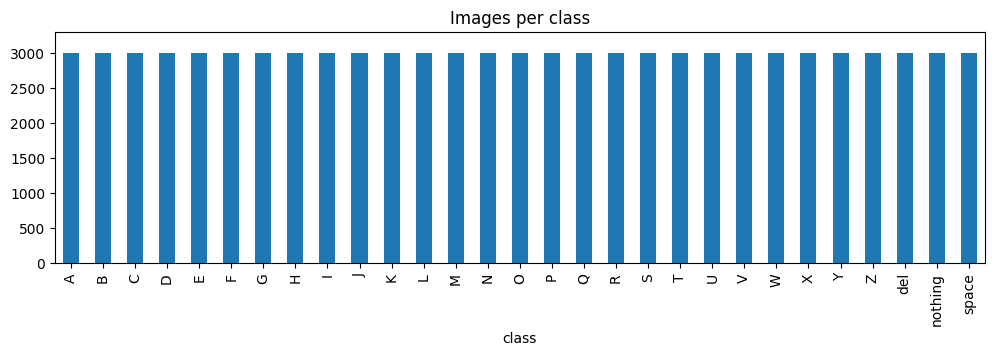

In [4]:
print("Total images:        ", stats["n_files"].sum())
print("Non-.jpg files:      ", (stats["n_files"] - stats["n_jpg"]).sum())
print("Distinct sizes:      ", set().union(*stats["sizes"]))
print("Distinct color modes:", set().union(*stats["modes"]))
print("Smallest / largest class:", stats["n_files"].min(), "/", stats["n_files"].max())

# Every filename should be <class><number>.jpg - otherwise frame_number() would crash later.
odd = [
    p.name
    for c in classes
    for p in (TRAIN_ROOT / c).glob("*")
    if not p.stem.removeprefix(c).isdigit()
]
print("Filenames that don't match <class><number>:", odd[:10], f"({len(odd)} total)")

ax = stats["n_files"].plot.bar(figsize=(12, 3), title="Images per class")
ax.set_ylim(0, stats["n_files"].max() * 1.1)  # start at 0 so small differences are not exaggerated
plt.show()

### Why the threaded version replaced the first attempt (a mistake kept on purpose)

The first version opened every file one after another and took about **5 minutes**:

```python
for c in classes:
    folder = root / c
    sizes, modes = [], []
    for f in folder.glob("*"):
        with Image.open(f) as img:
            sizes.append(img.size)
            modes.append(img.mode)
```

The threaded version took about **13.8 seconds** with identical output. But that comparison is not fully fair: Windows caches recently read files in memory, so the second run benefits from the first run's reads. The cell below times both approaches on one class, twice. **Run 2 is the fair comparison**, because both approaches then read from a warm cache.

In [5]:
def sequential_check(files):
    return [get_info(f) for f in files]


def threaded_check(files, workers=8):
    with ThreadPoolExecutor(max_workers=workers) as pool:
        return list(pool.map(get_info, files))


def seconds(fn, *args):
    t0 = time.perf_counter()
    fn(*args)
    return time.perf_counter() - t0


files_A = list((TRAIN_ROOT / "A").glob("*"))
for run in (1, 2):
    print(
        f"run {run}: sequential {seconds(sequential_check, files_A):.2f}s"
        f" | threaded {seconds(threaded_check, files_A):.2f}s"
    )

run 1: sequential 0.36s | threaded 0.44s
run 2: sequential 0.31s | threaded 0.36s


## 3. Looking at the images

Numbers do not tell you what the data *looks* like. First, one random image from every class, so we have seen every sign at least once. While looking, ask yourself:

- What do `del`, `nothing` and `space` look like? Is there a hand in the `nothing` image? (This matters: MediaPipe finds hands, so what will it return for an image with no hand?)
- Are the backgrounds and lighting consistent across classes, or do they vary?

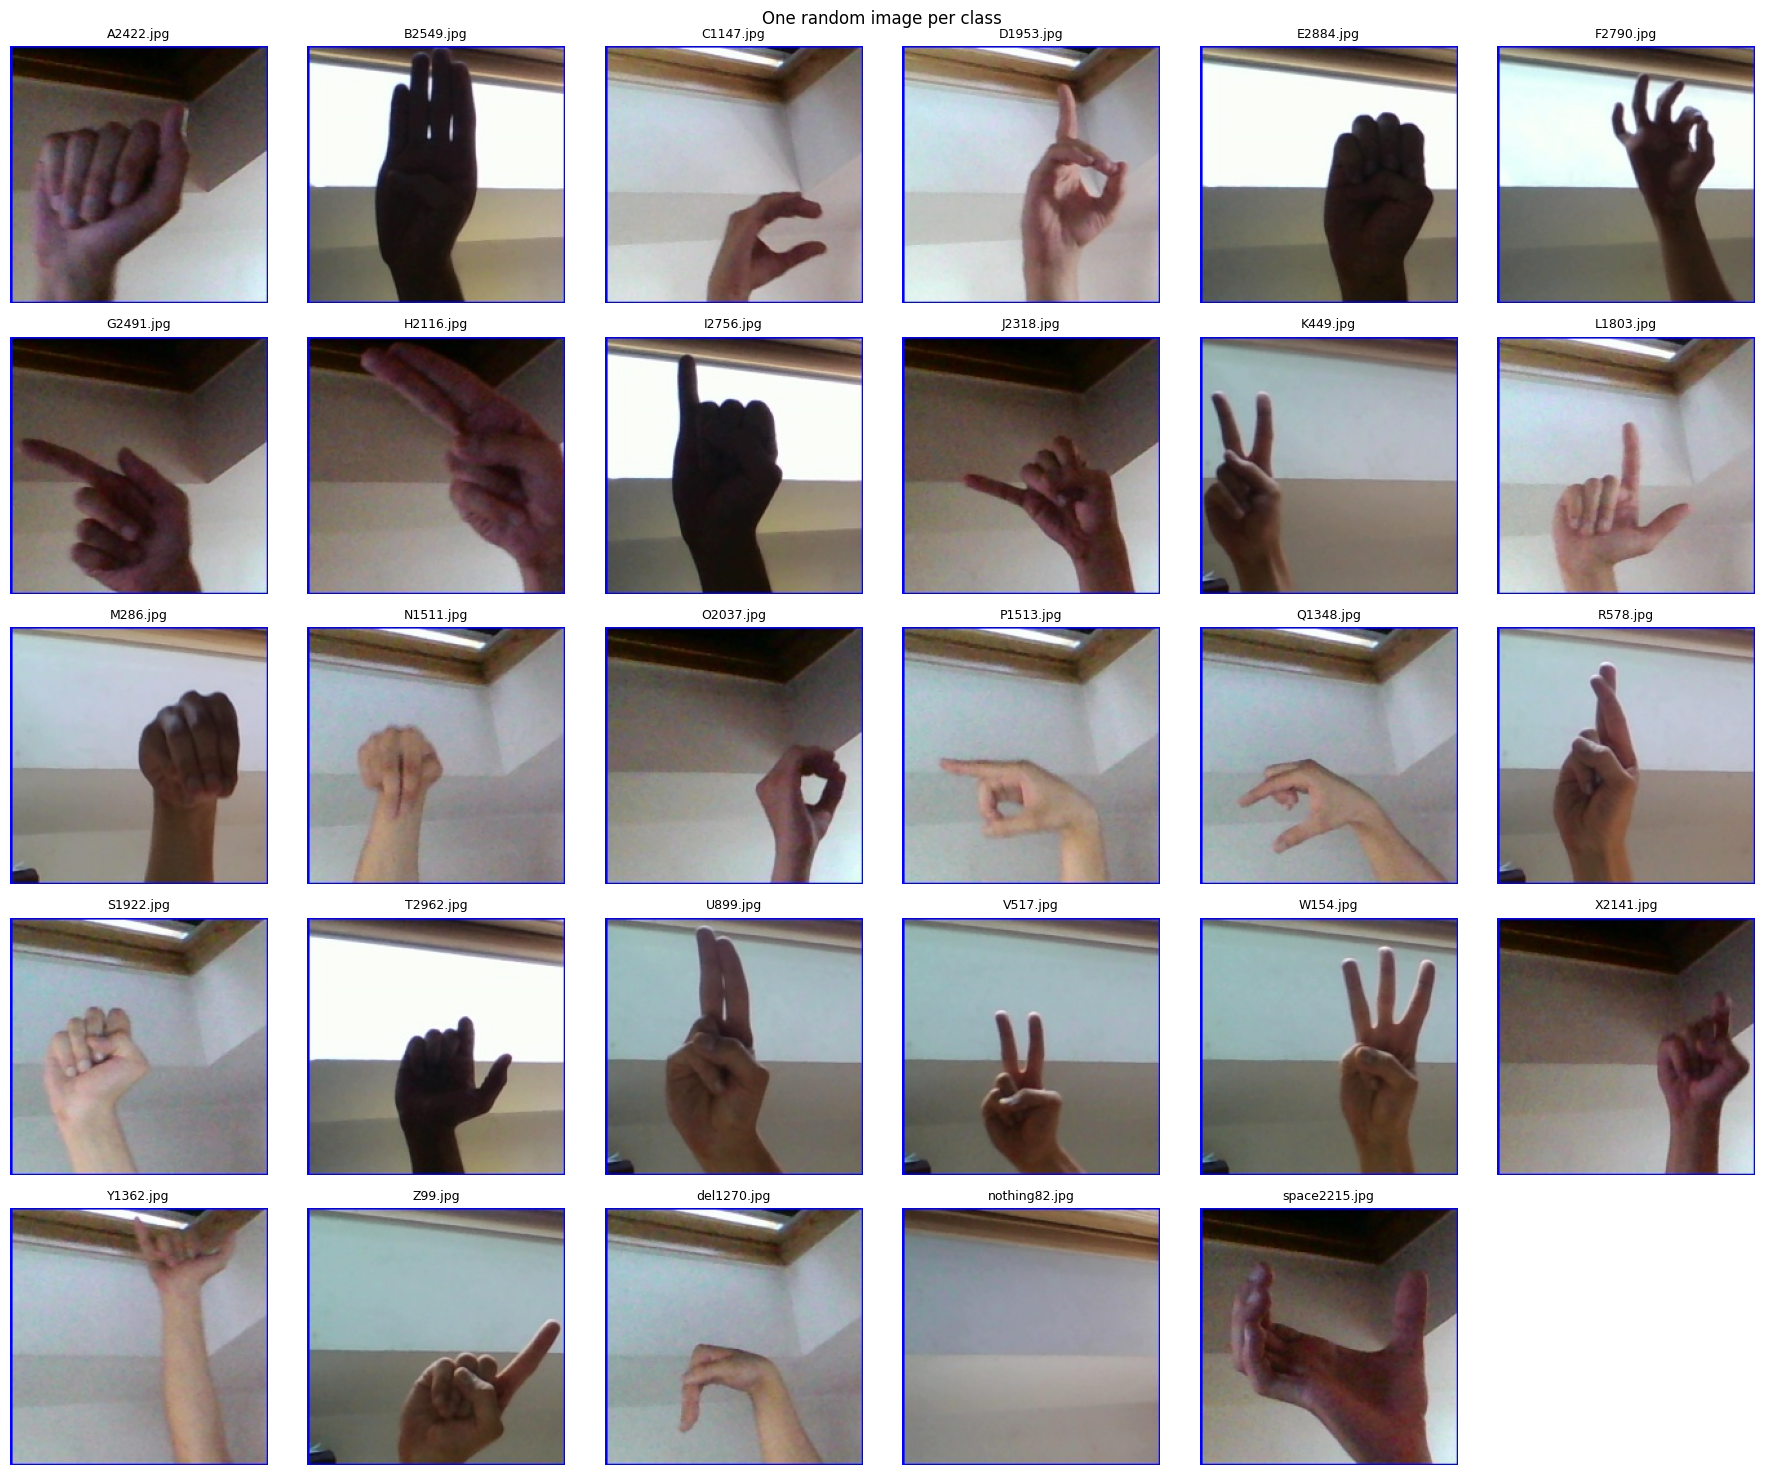

In [6]:
rng = random.Random(SEED)
one_per_class = [rng.choice(list((TRAIN_ROOT / c).glob("*.jpg"))) for c in classes]
show_images(one_per_class, ncols=6, title="One random image per class")

Next, five random images from each of a few classes. Random picks from a 3000-image folder usually land far apart, so this shows the *overall* variety of a class. It cannot tell us whether the folder is 3000 different shots or a few dozen short clips (that is section 4).

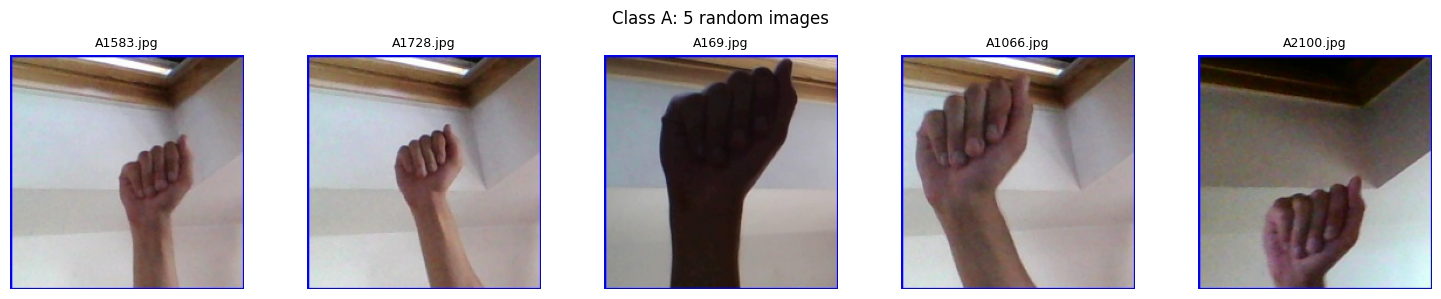

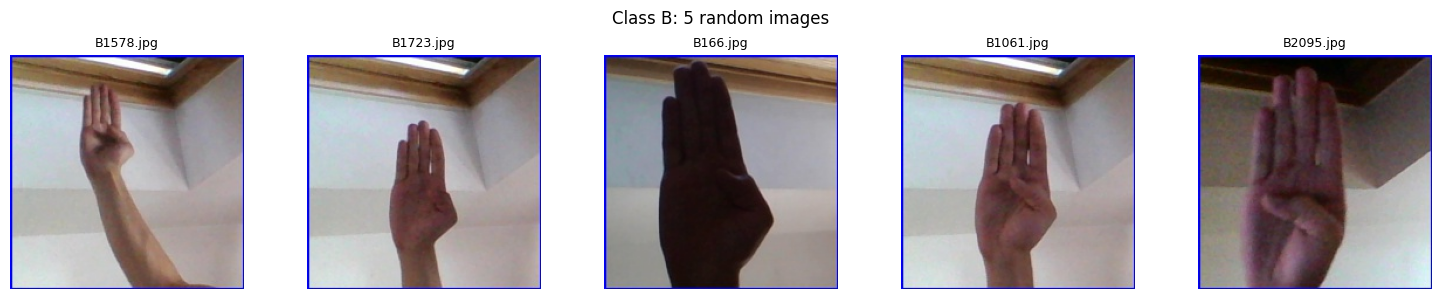

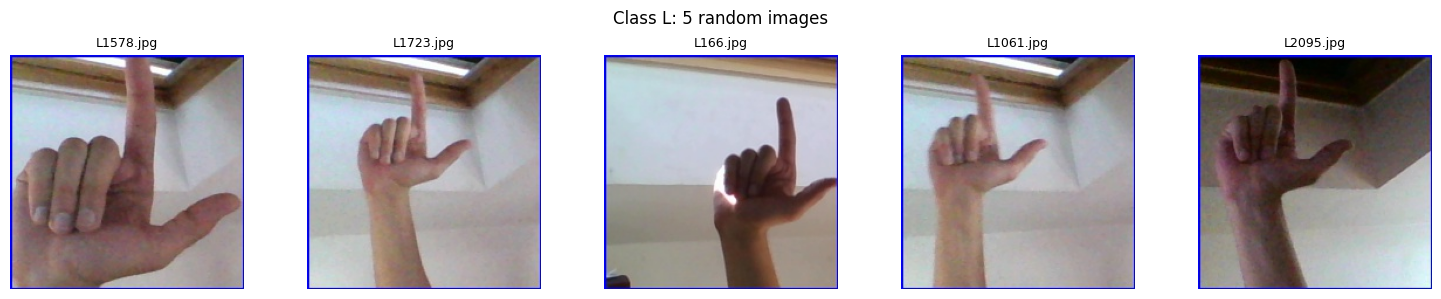

In [7]:
for c in ("A", "B", "L"):
    random_five = random.Random(SEED).sample(list_frames(c), 5)
    show_images(random_five, title=f"Class {c}: 5 random images")

## 4. Are the images near-duplicate video frames?

The README flagged that filenames like `B1.jpg ... B3000.jpg` look like a short clip cut into sequential frames. Random sampling cannot confirm that, so we compare two views of the same class:

- the first 5 **consecutive** frames, and
- 5 frames **evenly spaced** through the folder.

If consecutive frames are near-identical while the spaced ones differ a lot, the folder is a set of clips and the real pose diversity is far lower than 3000 images per class. First the actual filenames, to prove the numeric sort works (they should read 1, 2, 3, ...):

In [8]:
print([p.name for p in list_frames("B")[:10]])
print([p.name for p in list_frames("A")[:10]])

['B1.jpg', 'B2.jpg', 'B3.jpg', 'B4.jpg', 'B5.jpg', 'B6.jpg', 'B7.jpg', 'B8.jpg', 'B9.jpg', 'B10.jpg']
['A2.jpg', 'A3.jpg', 'A4.jpg', 'A5.jpg', 'A6.jpg', 'A7.jpg', 'A8.jpg', 'A9.jpg', 'A11.jpg', 'A12.jpg']


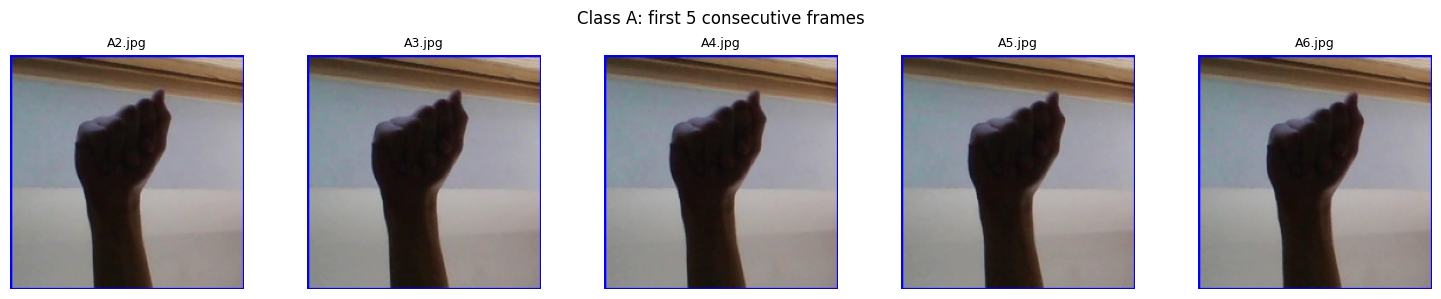

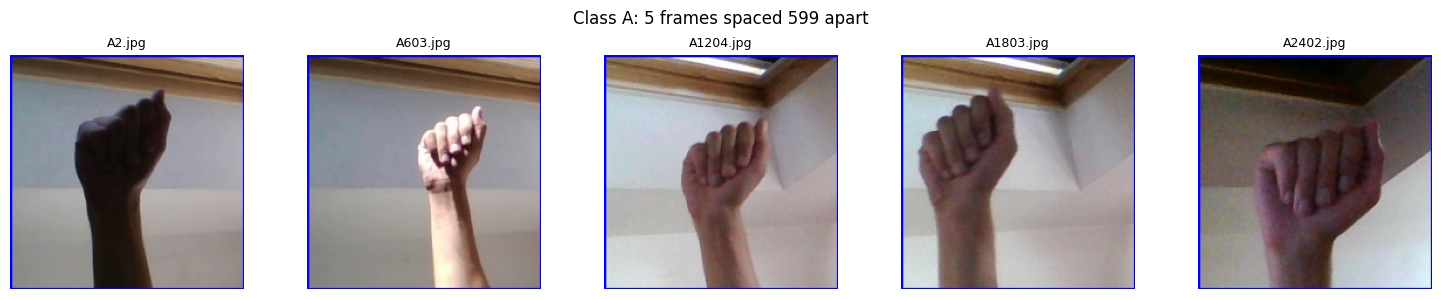

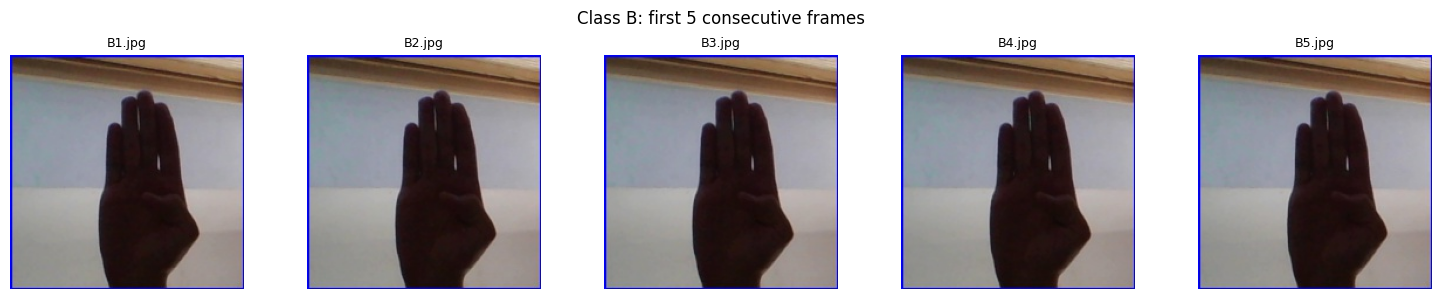

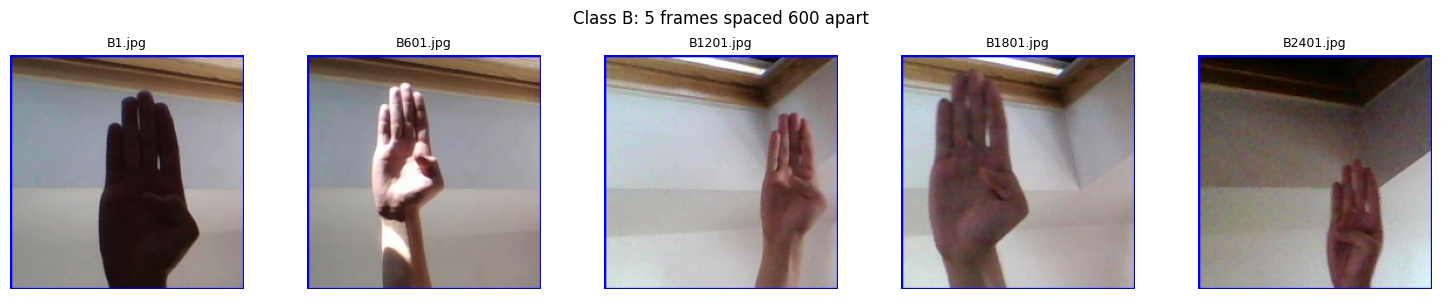

In [9]:
def show_consecutive_vs_spaced(cls, n=5):
    frames = list_frames(cls)
    step = len(frames) // n
    show_images(frames[:n], title=f"Class {cls}: first {n} consecutive frames")
    show_images(frames[::step][:n], title=f"Class {cls}: {n} frames spaced {step} apart")


show_consecutive_vs_spaced("A")
show_consecutive_vs_spaced("B")

### Putting a number on it

Eyeballing 5 images in 2 classes is weak evidence. Here we measure it for **every** class: the average absolute pixel difference (on grayscale images) between

- **neighbors** - frame *i* and frame *i+1*, and
- **random pairs** - two frames drawn from anywhere in the same class.

Their ratio (`random_diff / neighbor_diff`) says how much more alike neighbors are than random pairs. A ratio near 1 means neighbors are no more similar than any two random images, so the data really is diverse. A large ratio means heavy near-duplication.

This is a crude measure: lighting changes and a shifting background also raise the difference, and one number cannot describe a pose. Treat it as supporting evidence next to the pictures, not as proof. `nothing` is expected to behave differently, since it contains no hand to move.

In [10]:
def to_array(path):
    """Load an image as a float grayscale array."""
    with Image.open(path) as im:
        return np.asarray(im.convert("L"), dtype=np.float32)


def mean_gap_diff(frames, gap, n_samples=50):
    """Average pixel difference between frame i and frame i+gap, over random i."""
    rng = random.Random(SEED)
    starts = rng.sample(range(len(frames) - gap), min(n_samples, len(frames) - gap))
    return float(np.mean([np.abs(to_array(frames[i]) - to_array(frames[i + gap])).mean() for i in starts]))


def random_pair_diff(frames, n_pairs=50):
    """Average pixel difference between two random frames of the same class."""
    rng = random.Random(SEED)
    diffs = []
    for _ in range(n_pairs):
        a, b = rng.sample(frames, 2)
        diffs.append(np.abs(to_array(a) - to_array(b)).mean())
    return float(np.mean(diffs))


rows = []
for c in classes:
    frames = list_frames(c)
    neighbor, rand = mean_gap_diff(frames, 1), random_pair_diff(frames)
    rows.append({"class": c, "neighbor_diff": neighbor, "random_diff": rand, "ratio": rand / neighbor})

dup_stats = pd.DataFrame(rows).set_index("class").round(2)
display(dup_stats.sort_values("ratio"))
print(dup_stats["ratio"].describe().round(2))

,neighbor_diff,random_diff,ratio
class,,,
F,4.80,60.32,12.57
W,3.91,54.14,13.86
O,3.71,54.68,14.74
B,3.78,58.10,15.37
A,3.64,58.37,16.04
V,3.41,54.94,16.12
L,3.71,60.43,16.27
N,3.44,56.17,16.33
U,3.26,53.56,16.41


count    29.00
mean     17.38
std       2.41
min      12.57
25%      16.33
50%      17.33
75%      18.06
max      27.06
Name: ratio, dtype: float64


### How fast does a clip "forget" its starting pose?

If the folder is made of clips, the difference between frame *i* and frame *i+k* should grow as the gap *k* grows, then level off once the two frames are as different as random pairs (the dashed line). The gap where each curve levels off is roughly how long the "same pose" lasts. That number guides two later decisions: how far apart the frames we process should be, and how large the blocks should be when we split into train and validation sets so near-twins do not end up on both sides.

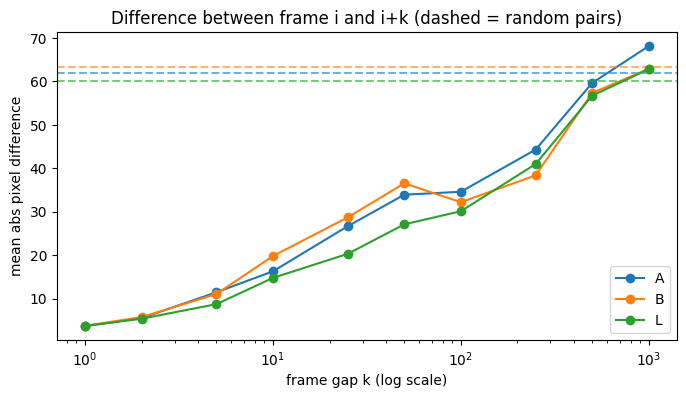

In [11]:
GAPS = [1, 2, 5, 10, 25, 50, 100, 250, 500, 1000]

fig, ax = plt.subplots(figsize=(8, 4))
for c in ("A", "B", "L"):
    frames = list_frames(c)
    gaps = [g for g in GAPS if g < len(frames)]
    line, = ax.plot(gaps, [mean_gap_diff(frames, g, n_samples=30) for g in gaps], marker="o", label=c)
    ax.axhline(random_pair_diff(frames, n_pairs=30), ls="--", color=line.get_color(), alpha=0.6)
ax.set_xscale("log")
ax.set_xlabel("frame gap k (log scale)")
ax.set_ylabel("mean abs pixel difference")
ax.set_title("Difference between frame i and i+k (dashed = random pairs)")
ax.legend()
plt.show()

## 5. The test split

The dataset ships a tiny test folder (the README predicted ~29 images, one per class). We check that its filenames match the training classes and that the images have the same size and mode, then look at all of them. The labels here come from the filename, `<label>_test.jpg`.

28 test images
['A_test.jpg', 'B_test.jpg', 'C_test.jpg', 'D_test.jpg', 'E_test.jpg', 'F_test.jpg', 'G_test.jpg', 'H_test.jpg', 'I_test.jpg', 'J_test.jpg', 'K_test.jpg', 'L_test.jpg', 'M_test.jpg', 'N_test.jpg', 'nothing_test.jpg', 'O_test.jpg', 'P_test.jpg', 'Q_test.jpg', 'R_test.jpg', 'S_test.jpg', 'space_test.jpg', 'T_test.jpg', 'U_test.jpg', 'V_test.jpg', 'W_test.jpg', 'X_test.jpg', 'Y_test.jpg', 'Z_test.jpg']
Labels match training classes: False
Missing: {'del'} | Extra: set()
Distinct (size, mode): {((200, 200), 'RGB')}


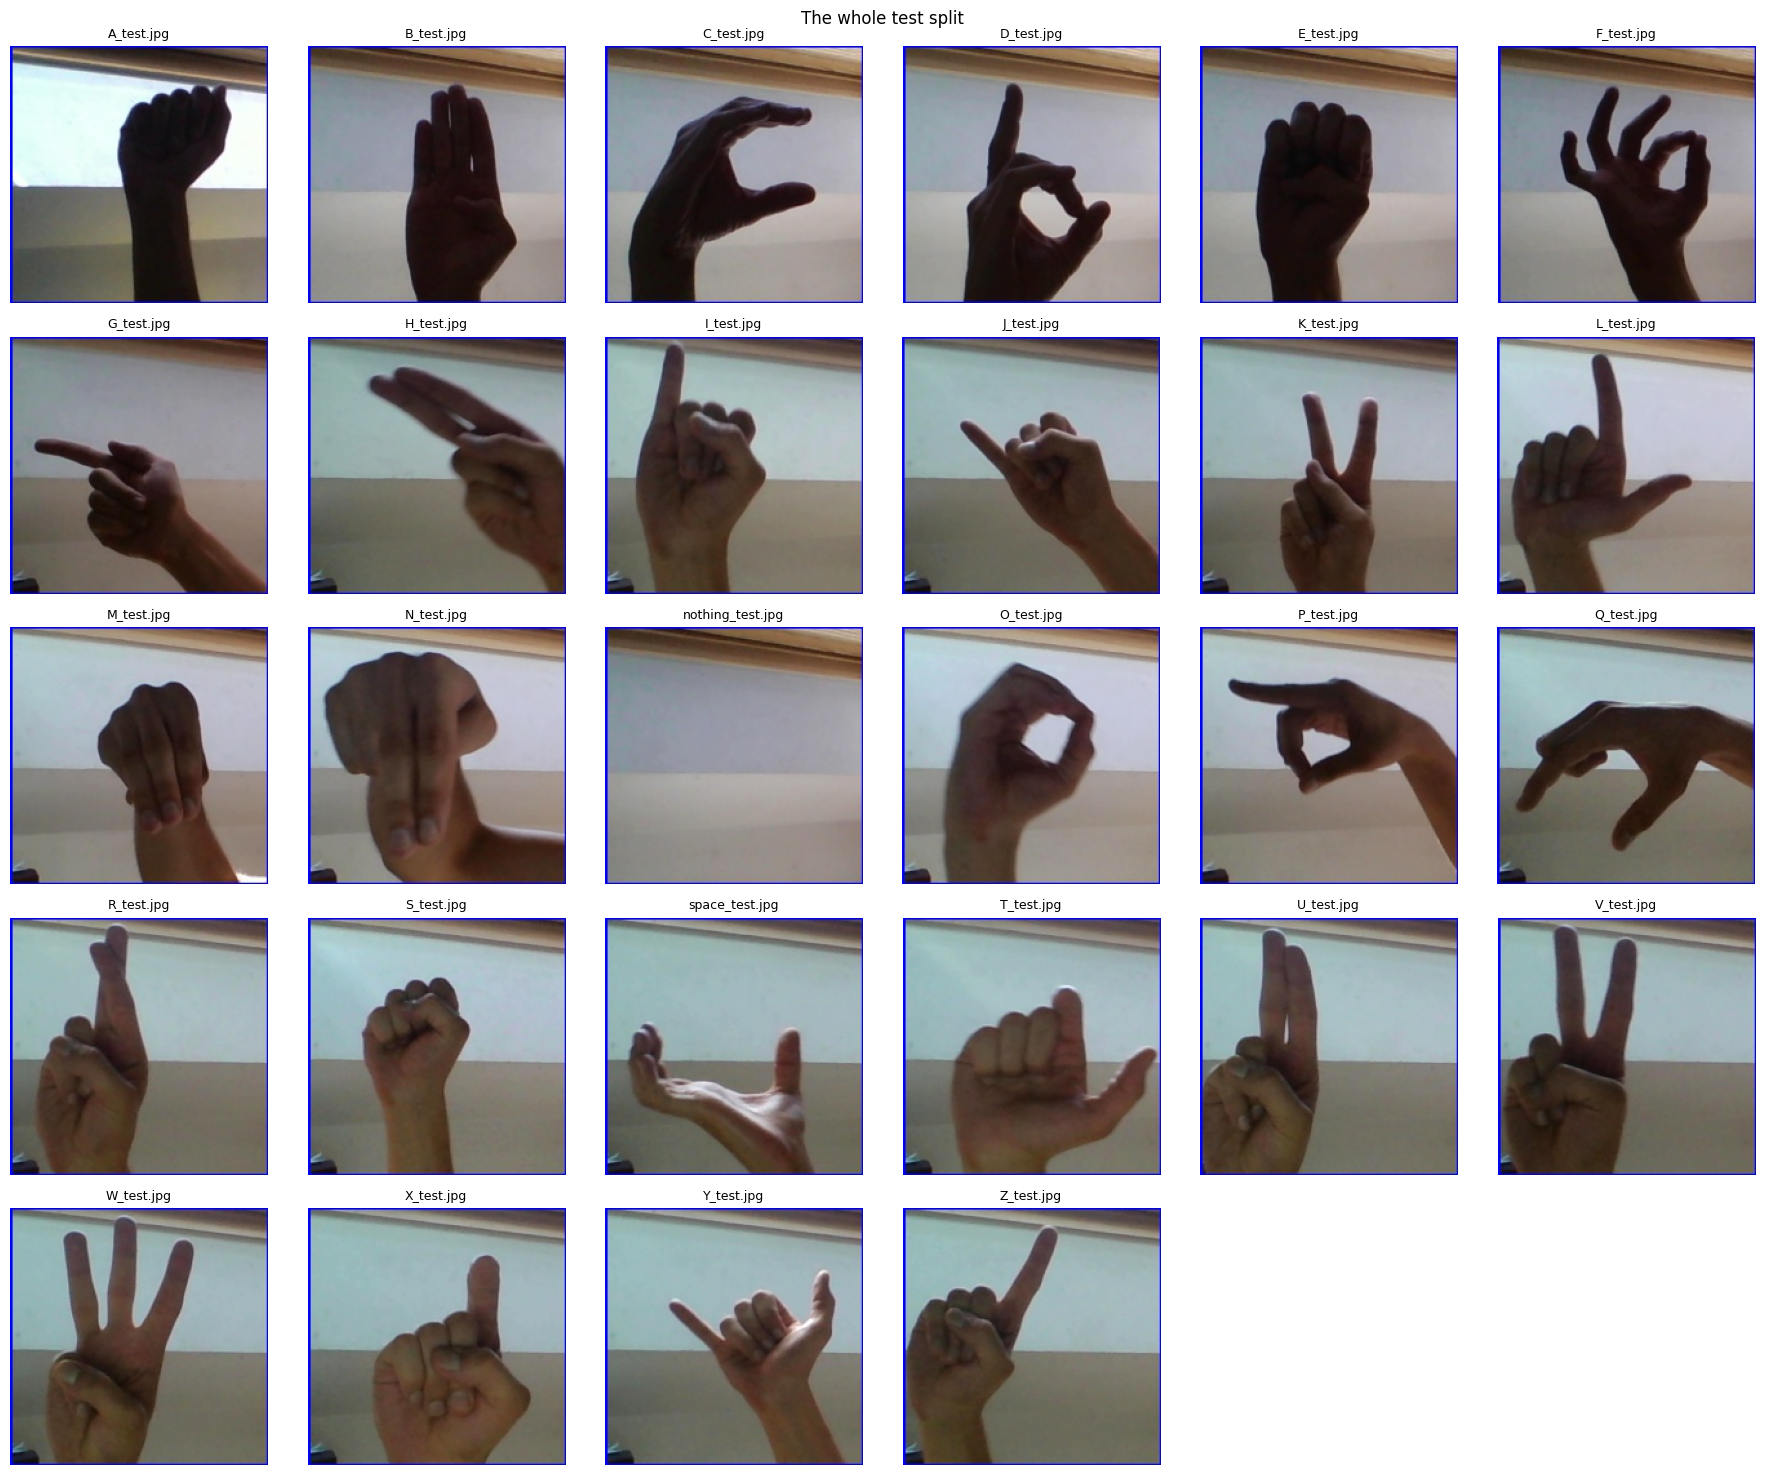

In [12]:
test_files = sorted(TEST_ROOT.glob("*.jpg"))
assert test_files, f"No .jpg files in {TEST_ROOT.resolve()} - check for a nested folder"

test_labels = {p.stem.removesuffix("_test") for p in test_files}
print(len(test_files), "test images")
print([p.name for p in test_files])
print("Labels match training classes:", test_labels == set(classes))
print("Missing:", set(classes) - test_labels, "| Extra:", test_labels - set(classes))
print("Distinct (size, mode):", {get_info(p) for p in test_files})

show_images(test_files, ncols=6, title="The whole test split")

## 6. Findings (write this part yourself)

Fill in each prompt in your own words, citing numbers from the cells above. Write it as if for someone who has not seen the notebook - it is the first thing you will re-read when you come back.

- **What I checked:** _...one line per section above..._
- **What I found:** _classes and counts; sizes and modes; what neighbors vs spaced frames showed; the neighbor-vs-random ratio; where the decay curve levels off; what the test split contains..._
- **What surprised me:** _...anything that did not match the README's expectations, including the `nothing` class and class A's missing files..._
- **What this changes about the plan:** _consider: how to split train/validation, how many frames per class to run through MediaPipe, what to do about `nothing`, whether the 29-image test split is useful, and whether `J` and `Z` look like they can be captured in a still image..._

We checked all the data in both test and train to see if the data is fairly nice. We also see what is the fastest way to read the data.

So we realize the neighbours are almost near duplicates because the ratio is almost 17 indicating that the relationship between 2 random frames is 17 times more than 2 frames similar to eachother.

We also cannot use the test folder coz we noticed it misses some letters (the del) and now it is very dumb becaus I think they just got one picture from the test folder and pasted it.....

We also look at the graph and we see the plots start to defer around that 60 frame mark where all the 3 graphs a, b and l which means if we did a simple test train split what we will end up with a near perfect frame in both test and train and make our evals garbage. So what we go with is this when we make splits in contguous blocks like 100 frames.
